# 09. Monitoring the forecast

**Where we are:** the model runs as a service (`src/gb_demand/api.py`) and makes a forecast each
day. Notebook 08 measured how good it was over the test window. A live forecast also needs a way
to notice when it stops being that good.

**What can go wrong, and how each would show up:**

| What changes | Example | Check |
|---|---|---|
| The inputs move outside what the model learnt from | solar capacity keeps growing; demand keeps falling | drift of each feature (PSI) |
| A data feed changes | the weather provider changes its model | drift of the weather features |
| The link between inputs and demand changes | new heat pumps make demand more sensitive to cold | accuracy against NESO |
| The intervals stop meaning what they say | errors grow, but the intervals were set on calmer months | 90% interval coverage |

Accuracy can only be checked once outturn is published (the next day). Drift can be checked as
soon as the inputs arrive, before anything goes wrong, but drift does not always hurt. So both
are needed.

The functions live in `src/gb_demand/monitor.py`; this notebook explains them and runs them over
the 30 test months.

**Background reading**
- [Evidently: what is data drift](https://www.evidentlyai.com/ml-in-production/data-drift) and
  [what is concept drift](https://www.evidentlyai.com/ml-in-production/concept-drift)
- [Yurdakul (2018), Statistical properties of the population stability index](https://scholarworks.wmich.edu/dissertations/3208/)


## Step 1. Set up and load

**What:** the training features (ERA5 weather), the features the test forecasts used (forecast
weather), and the test forecasts from the pipeline's backtest stage.


In [1]:
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from gb_demand.monitor import (COVERAGE_BAND, DRIFT_FEATURES, PSI_LARGE, PSI_MODERATE, TREND_FEATURES,
                               VALIDATION_GAP_MW, alerts, feature_drift, markdown_report, performance, psi)

PROCESSED = Path("../data/processed")
REPORTS = Path("../reports")
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
plt.rcParams.update({
    "figure.dpi": 90,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": "#e4e4e0",
    "lines.linewidth": 2,
})

features = pd.read_parquet(PROCESSED / "features_actual.parquet")
forecast_features = pd.read_parquet(PROCESSED / "features_forecast.parquet")
test = pd.read_parquet(PROCESSED / "test_forecasts.parquet")

dates = pd.to_datetime(features["Date"])
reference = features[(dates >= "2019-01-01") & (dates < "2024-01-01")]
current = forecast_features[forecast_features["start_utc"].isin(test["start_utc"])]
print(f"reference: {len(reference):,} half-hours (2019 to 2023), current: {len(current):,} half-hours")


reference: 87,648 half-hours (2019 to 2023), current: 42,818 half-hours


## Step 2. Measuring drift: the population stability index

**What:** the PSI compares the distribution of a feature now with its distribution in a
reference period. Split the reference into ten equal-count bins (deciles), find the share of the
reference (`e`) and of the current data (`a`) in each bin, and add up

`PSI = Σ (a − e) × ln(a / e)`

It is zero when the shares match and grows as they move apart. The usual reading, from credit
scoring where it started: under 0.1 stable, 0.1 to 0.25 a moderate shift, over 0.25 a large one.

**Why the same calendar month:** demand and weather are seasonal. A July compared with whole
years will always look like drift, because July is warmer than the year. So each test month is
compared with the same calendar month in 2019 to 2023. The cell below shows the difference for
temperature.


In [2]:
month = pd.to_datetime(current["Date"]).dt.to_period("M")
naive = {str(p): psi(reference["temperature_2m"], g["temperature_2m"]) for p, g in current.groupby(month)}
matched = feature_drift(reference, current, ["temperature_2m"])["temperature_2m"]
compare = pd.DataFrame({"against all months": pd.Series(naive), "against the same month": matched})
print("months over the 'large' threshold:")
print((compare > PSI_LARGE).sum().to_string())
compare.round(2).head(8)


months over the 'large' threshold:
against all months        30
against the same month    12


,against all months,against the same month
2024-06,1.67,0.18
2024-07,2.98,0.15
2024-08,4.13,0.04
2024-09,1.21,0.15
2024-10,1.58,0.11
2024-11,1.91,0.14
2024-12,2.68,0.35
2025-01,4.70,0.48


**Found:** compared with whole years, temperature looks drifted in all 30 test months (PSI up to
4.7). Compared with the same calendar month, 12 months are over the "large" line. August 2024
shows the difference: 4.13 against all months, 0.04 against past Augusts. So seasonal matching
removes most of the false alarms, and it is used from here on.


## Step 3. Drift of each input, month by month

**What:** PSI of the seven inputs that can move (weather, the latest demand level, the week-old
demand, solar capacity, and radiation times capacity) for every test month, against the same
month in 2019 to 2023.

**What to expect:** calendar features cannot drift. Weather should be stable unless a month was
unusual or the forecast weather differs from ERA5. Solar capacity grows every year, so it should
drift, and it matters, because a tree model cannot predict outside the values it was trained on.


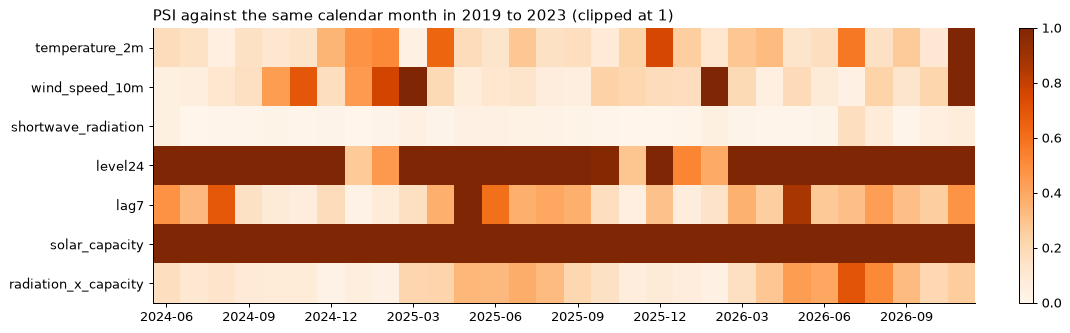

,median PSI,months moderate,months large
temperature_2m,0.17,15,12
wind_speed_10m,0.18,15,7
shortwave_radiation,0.01,1,0
level24,1.83,0,30
lag7,0.31,5,19
solar_capacity,8.23,0,30
radiation_x_capacity,0.19,9,11


In [3]:
drift = feature_drift(reference, current)

fig, ax = plt.subplots(figsize=(12, 3.8))
image = ax.imshow(drift.T.clip(upper=1).to_numpy(), aspect="auto", cmap="Oranges", vmin=0, vmax=1)
ax.set_yticks(range(len(DRIFT_FEATURES)), DRIFT_FEATURES)
ax.set_xticks(range(0, len(drift), 3), drift.index[::3])
ax.grid(False)
ax.set_title("PSI against the same calendar month in 2019 to 2023 (clipped at 1)", loc="left")
fig.colorbar(image, ax=ax, fraction=0.02)
fig.tight_layout()
plt.show()

summary = pd.DataFrame({
    "median PSI": drift.median(),
    "months moderate": ((drift >= PSI_MODERATE) & (drift < PSI_LARGE)).sum(),
    "months large": (drift >= PSI_LARGE).sum(),
})
summary.round(2)


In [4]:
latest_capacity = current["solar_capacity"].max()
print(f"largest solar capacity in training (2019 to 2023): {reference['solar_capacity'].max():,.0f} MW")
print(f"largest solar capacity in the test window:        {latest_capacity:,.0f} MW")
outside = current["solar_capacity"] > reference["solar_capacity"].max()
print(f"test half-hours with capacity above anything in training: {outside.mean():.0%}")


largest solar capacity in training (2019 to 2023): 16,747 MW
largest solar capacity in the test window:        23,963 MW
test half-hours with capacity above anything in training: 100%


**Is the weather drift real weather, or the forecast feed?** The model trains on ERA5 and is
fed forecasts. If the two differ in distribution, the drift table would show it even in ordinary
months. The cell below runs the same check on ERA5 for the same half-hours, and compares the
forecasts with ERA5 directly. It also checks how far each monthly refit had to go beyond the
solar capacity it was trained on, since trees hold the prediction flat beyond that.


In [5]:
weather = ["temperature_2m", "wind_speed_10m", "shortwave_radiation"]
era5_now = features[features["start_utc"].isin(test["start_utc"])]
drift_era5 = feature_drift(reference, era5_now, weather)
print(pd.DataFrame({"large months, ERA5": (drift_era5 >= PSI_LARGE).sum(),
                    "large months, forecast": (drift[weather] >= PSI_LARGE).sum()}).to_string())

paired = current.merge(era5_now[["start_utc", *weather]], on="start_utc", suffixes=("", "_era5"))
for name in weather:
    print(f"{name}: forecast minus ERA5, mean {(paired[name] - paired[name + '_era5']).mean():.2f}")

train_dates = pd.to_datetime(features["Date"])
beyond = []
for start in pd.to_datetime(sorted(test["fold"].unique())):
    seen = features.loc[(train_dates <= start - pd.Timedelta(days=7)) & features["ND"].notna(), "solar_capacity"].max()
    rows = current[pd.to_datetime(current["Date"]).dt.to_period("M") == start.to_period("M")]["solar_capacity"]
    beyond.append({"above": (rows > seen).mean(), "by": (rows - seen).clip(lower=0).mean()})
beyond = pd.DataFrame(beyond)
print(f"test rows with solar capacity above the refit's training maximum: {beyond['above'].mean():.0%}, "
      f"by {beyond['by'].mean():.0f} MW on average")


                     large months, ERA5  large months, forecast
temperature_2m                        5                      12
wind_speed_10m                        8                       7
shortwave_radiation                   0                       0
temperature_2m: forecast minus ERA5, mean -0.06
wind_speed_10m: forecast minus ERA5, mean -1.35
shortwave_radiation: forecast minus ERA5, mean 7.97


test rows with solar capacity above the refit's training maximum: 92%, by 190 MW on average


**Found:**

- **Trends drift, as expected:** the latest demand level and solar capacity are "large" in every
  month, and the week-old demand in 19. Solar capacity in the test window reaches 23,963 MW,
  against 16,747 MW at most in 2019 to 2023.
- **But the model is refitted monthly**, so what matters is how far each refit had to go beyond
  what it was trained on: 92% of test half-hours are above the refit's largest capacity, by only
  190 MW on average (about 1%). Small, but it is extrapolation that a tree cannot do, and it grows
  between refits.
- **Radiation never drifts** (0 large months). Wind is large in 7 months, temperature in 12.
- **Half of the temperature drift is the forecast feed, not the weather:** the same check on
  ERA5 for the same half-hours finds 5 large months, not 12. The mean differs by only 0.06 °C,
  so the forecasts differ from ERA5 elsewhere in the distribution (not looked at further here).
  For wind the counts are close (8 with ERA5, 7 with forecasts), so wind drift is mostly real
  weather, although the forecasts read 1.35 km/h lower than ERA5 on average.
- November 2026 has only nine days, so its values are noisy.


## Step 4. Forecast quality over time

**What:** for each test month, MAE of our forecast and of NESO's, the gap between them, and the
share of outcomes inside the 90% interval.

**What a warning looks like:** the gap to NESO was 174 MW on validation (notebook 06). A month
with a gap over twice that, or coverage outside 85% to 95%, deserves a look.


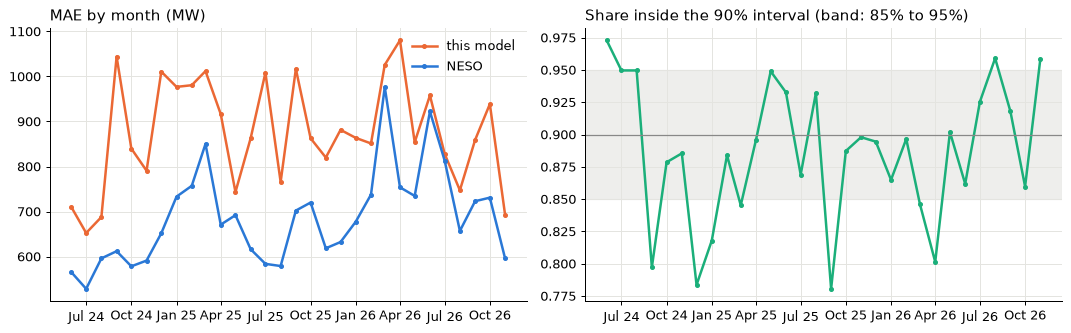

months with gap over twice the validation gap: 3
months with coverage outside the band: 10 of 30
mean gap to NESO, first 15 months 226 MW, last 15 152 MW


In [6]:
quality = performance(test)
index = pd.to_datetime(quality.index)

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].plot(index, quality["MAE"], color=ORANGE, marker="o", markersize=3, label="this model")
axes[0].plot(index, quality["NESO MAE"], color=BLUE, marker="o", markersize=3, label="NESO")
axes[0].set_title("MAE by month (MW)", loc="left")
axes[0].legend(frameon=False)
axes[1].plot(index, quality["90% coverage"], color=AQUA, marker="o", markersize=3)
axes[1].axhspan(*COVERAGE_BAND, color="#e4e4e0", alpha=0.6)
axes[1].axhline(0.9, color="#888", linewidth=1)
axes[1].set_title("Share inside the 90% interval (band: 85% to 95%)", loc="left")
for ax in axes:
    ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 4, 7, 10]))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %y"))
fig.tight_layout()
plt.show()

print("months with gap over twice the validation gap:", int((quality["gap to NESO"] > 2 * VALIDATION_GAP_MW).sum()))
print("months with coverage outside the band:",
      int((~quality["90% coverage"].between(*COVERAGE_BAND)).sum()), "of", len(quality))
first, second = quality.iloc[:15], quality.iloc[15:]
print(f"mean gap to NESO, first 15 months {first['gap to NESO'].mean():.0f} MW, last 15 {second['gap to NESO'].mean():.0f} MW")


**Found:**

- **The gap to NESO was over twice the validation gap in 3 months:** September 2024 (432 MW),
  December 2024 (359 MW) and July 2025 (424 MW).
- **Monthly 90% coverage is outside 85% to 95% in 10 of 30 months**, although it is 88.5% over the
  whole window. Seven months are low (down to 78% in December 2024 and September 2025) and three
  are high.
- **Low coverage comes with high error:** the low months are the months where MAE jumps (September
  2024, December 2024, September 2025, April 2026); across all months the correlation between
  MAE and coverage is −0.89. The intervals are set from the previous six months, so they lag a
  sudden rise in errors. Right on average, slow to react.
- The gap to NESO narrowed over time: 226 MW in the first 15 months, 152 MW in the last 15.


## Step 5. Alerts and what each would trigger

**What:** collect the flags in one table. In live use this would run each morning, after the
previous day's outturn is published.

**Which drift should alert:** the latest level, the week-old demand and solar capacity drift
in most months, because demand is falling and solar is growing. Radiation times capacity follows
capacity (radiation alone never drifts). These trends are known, and the monthly refit deals with
them. Alerting on them would bury the useful flags, so these four are kept in the report but do
not raise alerts.

| Flag | Likely cause | Action |
|---|---|---|
| Large drift in a weather feature | the forecast feed changed, or an unusual month | check the feed against ERA5; no action if the weather was simply unusual |
| Large drift in solar capacity or level | the system has moved beyond the training data | expected; check accuracy, retrain |
| Coverage outside 85% to 95% | errors changed faster than the six-month calibration window | recalibrate on a shorter window |
| Gap to NESO over twice the validation gap | something the model does not know about (holidays, a cold spell) | look at the worst days first |

The model is already refitted every month, which handles slow drift; the alerts are for what a
monthly refit does not fix.


In [7]:
every_drift = int((drift >= PSI_LARGE).sum().sum())
print(f"large-drift cells if every feature could alert: {every_drift}, of which trend features: "
      f"{int((drift[TREND_FEATURES] >= PSI_LARGE).sum().sum())}")
flagged = alerts(drift, quality, reference_gap=VALIDATION_GAP_MW)
print(flagged["check"].value_counts().to_string())
flagged[~flagged["check"].str.startswith("drift")]


large-drift cells if every feature could alert: 109, of which trend features: 90
check
drift: temperature_2m                        12
90% coverage outside 85-95%                  10
drift: wind_speed_10m                         7
gap to NESO over twice the validation gap     3


,month,check,value
19,2024-06,90% coverage outside 85-95%,0.973
20,2024-09,90% coverage outside 85-95%,0.797
21,2024-09,gap to NESO over twice the validation gap,432.000
22,2024-12,90% coverage outside 85-95%,0.784
23,2024-12,gap to NESO over twice the validation gap,359.000
24,2025-01,90% coverage outside 85-95%,0.818
25,2025-03,90% coverage outside 85-95%,0.845
26,2025-07,gap to NESO over twice the validation gap,424.000
27,2025-09,90% coverage outside 85-95%,0.781
28,2026-03,90% coverage outside 85-95%,0.846


**Found:** of 109 large-drift cells, 90 are the four trend features. Leaving those out leaves 32
flags over 30 months: 19 weather drift (12 temperature, 7 wind), 10 coverage and 3 gaps to NESO.
That is about one a month, few enough to read. The first version alerted on every feature and
would have raised more than three flags a month, nearly all about trends everyone already knew.


## Step 6. Save the report

**What:** write the same tables to `reports/monitoring.md`, which is committed with the code.
`python -m gb_demand.monitor` rebuilds it after each backtest.


In [8]:
REPORTS.mkdir(exist_ok=True)
(REPORTS / "monitoring.md").write_text(markdown_report(drift, quality, flagged))
print((REPORTS / "monitoring.md").read_text()[:600])


# Monitoring report

Built by `python -m gb_demand.monitor` from the backtest output.
Notebook 09 explains each check.

PSI bands: under 0.1 stable, 0.1 to 0.25 moderate, over 0.25 large. Each month is compared with the same calendar month in 2019 to 2023.

## Alerts

| month   | check                                     |   value |
|:--------|:------------------------------------------|--------:|
| 2024-10 | drift: wind_speed_10m                     |   0.44  |
| 2024-11 | drift: wind_speed_10m                     |   0.69  |
| 2024-12 | drift: temperature_2m                     |   0.35  |
|


## Summary

**What monitoring adds:** drift checks warn before outturn is known, and accuracy and coverage
checks confirm whether the drift mattered. Both run from `src/gb_demand/monitor.py`, and the
report is saved to `reports/monitoring.md`.

**What I learnt**
- Compare a seasonal input with the same month in past years. Against whole years, every month
  looks drifted.
- Some inputs drift by design (falling demand, growing solar). Report them, but do not alert on
  them, or the alerts stop being read.
- Half of the temperature drift came from the difference between the forecast feed and the ERA5
  data the model was trained on, not from unusual weather. That is a train and serve gap worth
  closing: training on archived forecasts once there are enough years of them.
- The intervals are right on average (88.5%) but slow to react: coverage fell to 78% in the worst
  months. A shorter calibration window, or one weighted to recent errors, is the next thing to try.

**Next (Day 11):** final write-up of results and limits.
